# Amazon India Smartphones Under ₹20K: Price, Rating & Discount Analysis
**Author:** Manish  
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Data:** Amazon.in search results scraped in October 2026 (221 smartphone listings)

## Business Questions
1. Which smartphone brand makes the most affordable phones under ₹20,000?
2. Which brand offers the best RAM in the ₹18,000-₹20,000 range?
3. Which phone is the best and most affordable buy, based on rating and number of users who purchased it?
4. Which brand gives the maximum discount during the festival sale?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [2]:
url = "https://raw.githubusercontent.com/officialmanish03/Python_A1/refs/heads/main/amazon_phones_dataset.csv"
df = pd.read_csv(url)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 221 entries, 0 to 220
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   product_name       221 non-null    str    
 1   brand              221 non-null    str    
 2   ram_gb             221 non-null    int64  
 3   selling_price      195 non-null    float64
 4   mrp                169 non-null    float64
 5   discount_pct       169 non-null    float64
 6   rating             215 non-null    float64
 7   rating_count       215 non-null    float64
 8   bought_past_month  140 non-null    float64
 9   sale_badge         55 non-null     str    
dtypes: float64(6), int64(1), str(3)
memory usage: 17.4 KB


In [4]:
df.head()

,product_name,brand,ram_gb,selling_price,mrp,discount_pct,rating,rating_count,bought_past_month,sale_badge
0,"Samsung Galaxy M17e 5G Mobile (Blitz Blue, 6GB...",Samsung,6,19499.0,NaN,NaN,4.1,1300.0,2000.0,NaN
1,"Samsung Galaxy M47 5G Mobile (Blaze Blue, 6GB ...",Samsung,6,26999.0,46999.0,43.0,3.1,826.0,2000.0,Previously viewed
2,OnePlus N6 | 6GB+128GB | Midnight Green | Segm...,OnePlus,6,24999.0,33999.0,26.0,3.9,1400.0,5000.0,Great Indian Festival
3,"Motorola G57 Power 5G (Fluidity, 8GB RAM, 128G...",Motorola,8,22495.0,NaN,NaN,4.2,1200.0,5000.0,NaN
4,OnePlus N6 Lite 4G | 4GB+64GB | Midnight Hype ...,OnePlus,4,15999.0,24999.0,36.0,3.1,62.0,NaN,Great Indian Festival


In [5]:
df.shape

(221, 10)

In [6]:
df.isnull().sum()

product_name           0
brand                  0
ram_gb                 0
selling_price         26
mrp                   52
discount_pct          52
rating                 6
rating_count           6
bought_past_month     81
sale_badge           166
dtype: int64

In [7]:
df.describe()

,ram_gb,selling_price,mrp,discount_pct,rating,rating_count,bought_past_month
count,221.000000,195.000000,169.000000,169.000000,215.000000,215.000000,140.000000
mean,6.895928,29904.195077,43469.366864,28.218935,3.973953,722.590698,1930.714286
std,2.397543,19029.109601,25514.735668,13.829510,0.462693,1428.679127,1874.224883
min,3.000000,8099.000000,11499.000000,1.000000,1.000000,1.000000,50.000000
25%,6.000000,19739.500000,29999.000000,17.000000,3.800000,70.000000,200.000000
50%,6.000000,24999.000000,36999.000000,30.000000,4.100000,330.000000,1000.000000
75%,8.000000,31799.000000,49999.000000,40.000000,4.300000,826.000000,4000.000000
max,16.000000,129999.000000,169999.000000,57.000000,5.000000,17400.000000,5000.000000


## 1. Data Preparation

In [8]:
df.duplicated(subset="product_name").sum()

np.int64(21)

In [9]:
df = df.drop_duplicates(subset="product_name").reset_index(drop=True)
df.shape

(200, 10)

In [10]:
df["selling_price"].isnull().sum()

np.int64(25)

In [11]:
df_20k = df[df["selling_price"] <= 20000].copy()
df_20k.shape

(48, 10)

In [12]:
df_20k.isnull().sum()

product_name          0
brand                 0
ram_gb                0
selling_price         0
mrp                   6
discount_pct          6
rating                0
rating_count          0
bought_past_month    12
sale_badge           36
dtype: int64

In [13]:
df_20k["brand"].value_counts()

brand
Samsung     11
OPPO        10
Lava         8
Redmi        5
Motorola     4
vivo         3
OnePlus      2
realme       2
Tecno        1
Alcatel      1
Poco         1
Name: count, dtype: int64

In [14]:
df_20k["selling_price"].describe()

count       48.000000
mean     16918.208333
std       3009.732058
min       8099.000000
25%      15999.000000
50%      17773.500000
75%      18901.500000
max      19999.000000
Name: selling_price, dtype: float64

## 2. Q1: Which Brand Offers the Most Affordable Phones Under ₹20,000?

In [15]:
brand_price = df_20k.groupby("brand")["selling_price"].agg(["count", "mean", "median", "min", "max"]).round(0)
brand_price.sort_values("median")

,count,mean,median,min,max
brand,,,,,
Lava,8,11624.0,11698.0,8099.0,14999.0
Alcatel,1,15990.0,15990.0,15990.0,15990.0
Redmi,5,16799.0,15999.0,15999.0,17999.0
Poco,1,16199.0,16199.0,16199.0,16199.0
OnePlus,2,17249.0,17249.0,15999.0,18499.0
Tecno,1,17499.0,17499.0,17499.0,17499.0
Motorola,4,18074.0,18106.0,17835.0,18249.0
OPPO,10,18433.0,18448.0,16999.0,19999.0
Samsung,11,18116.0,18450.0,15999.0,19999.0


In [16]:
brand_price[brand_price["count"] >= 3].sort_values("median")

,count,mean,median,min,max
brand,,,,,
Lava,8,11624.0,11698.0,8099.0,14999.0
Redmi,5,16799.0,15999.0,15999.0,17999.0
Motorola,4,18074.0,18106.0,17835.0,18249.0
OPPO,10,18433.0,18448.0,16999.0,19999.0
Samsung,11,18116.0,18450.0,15999.0,19999.0
vivo,3,18332.0,18999.0,15999.0,19999.0


In [17]:
df_priced = df.dropna(subset=["selling_price"]).copy()
df_priced["under_20k"] = df_priced["selling_price"] <= 20000

In [18]:
share = df_priced.groupby("brand")["under_20k"].agg(under_20k_count="sum", total_priced="count", pct="mean")
share["pct"] = (share["pct"] * 100).round(1)
share.sort_values("pct", ascending=False)

,under_20k_count,total_priced,pct
brand,,,
Alcatel,1,1,100.0
Lava,8,8,100.0
Tecno,1,2,50.0
Redmi,5,11,45.5
OPPO,10,27,37.0
Samsung,11,38,28.9
vivo,3,11,27.3
Motorola,4,20,20.0
Poco,1,6,16.7


In [19]:
pd.set_option("display.max_colwidth", 70)
df_20k[df_20k["brand"].isin(["Lava", "Redmi"])][["product_name", "ram_gb", "selling_price"]]

,product_name,ram_gb,selling_price
6,Redmi 15C 5G Prime Edition Dusk Purple 6GB + 128GB | Massive 6000m...,6,17999.0
13,"Lava Bold N4 Pro 5G (Opulent Lilac, 6GB RAM, 128GB Storage) | 50MP...",6,14999.0
30,"Redmi 15C 5G Prime Edition (Moonlight Blue, 6GB + 128GB) | Massive...",6,17999.0
32,"Lava Bold N4 Pro 5G (Monaco Blue, 6GB RAM, 128GB Storage) | 50MP A...",6,14999.0
57,"Lava Bold N2 (Indus Black, 4 GB RAM, 64 GB Storage) | 13MP AI Dual...",4,8899.0
58,"Redmi 15C 5G Prime Edition (Dusk Purple, 4GB + 128GB) | Massive 60...",4,15999.0
78,Redmi 15C 5G Prime Edition Midnight Black 4GB + 128GB | Massive 60...,4,15999.0
83,"Lava Bold N2 (Siachen White, 4 GB RAM, 64 GB Storage) | 13MP AI Du...",4,8899.0
86,"Lava Bold N2 Lite (Nilgiri Blue, 3 GB RAM, 64 GB Storage) | 6.75"" ...",3,8099.0
101,Redmi 15C 5G Prime Edition Moonlight Blue 4GB + 128GB | Massive 60...,4,15999.0


### Q1 Visualizations

Chart 1: Median price by brand

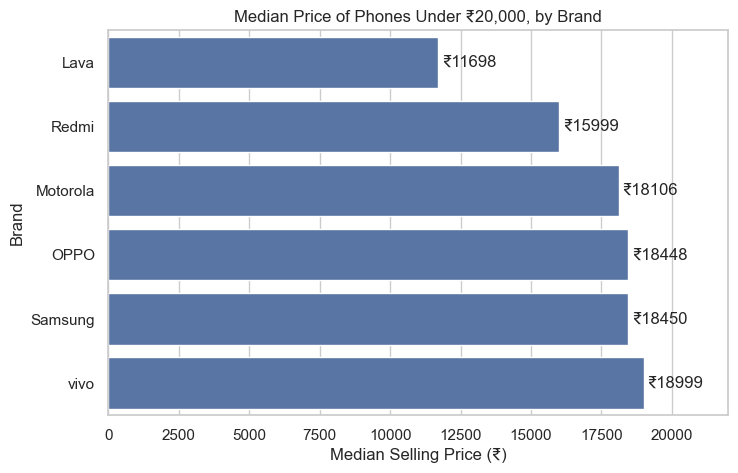

In [20]:
os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

plot_df = brand_price[brand_price["count"] >= 3].sort_values("median").reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=plot_df, x="median", y="brand", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="₹%.0f", padding=3)
plt.xlim(0, 22000)
plt.title("Median Price of Phones Under ₹20,000, by Brand")
plt.xlabel("Median Selling Price (₹)")
plt.ylabel("Brand")
plt.savefig("images/01_median_price_by_brand.png", dpi=150, bbox_inches="tight")
plt.show()

Chart 2: Share of phones priced at ₹20,000 or below

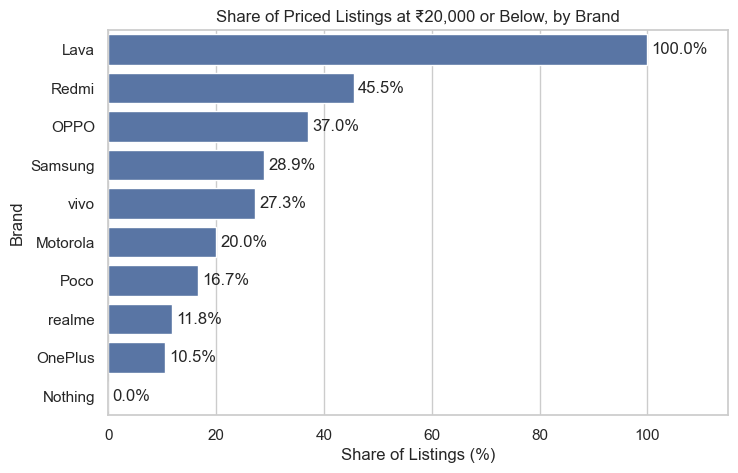

In [21]:
share_plot = share[share["total_priced"] >= 5].sort_values("pct", ascending=False).reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=share_plot, x="pct", y="brand", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.xlim(0, 115)
plt.title("Share of Priced Listings at ₹20,000 or Below, by Brand")
plt.xlabel("Share of Listings (%)")
plt.ylabel("Brand")
plt.savefig("images/02_share_under_20k_by_brand.png", dpi=150, bbox_inches="tight")
plt.show()

In [22]:
variants = df_20k.drop_duplicates(subset=["brand", "ram_gb", "selling_price"])
variants.groupby("brand").size().sort_values(ascending=False)

brand
OPPO        9
Samsung     8
Lava        4
Motorola    4
vivo        3
Redmi       2
OnePlus     2
Alcatel     1
Poco        1
Tecno       1
realme      1
dtype: int64

### Q1 Finding
- **Lava is the most affordable brand.** Among brands with at least 3 listings, Lava has the lowest median price (₹11,698) and the cheapest phone overall (₹8,099). All 8 of its priced listings are at or below ₹20,000.
- **Redmi is next** (median ₹15,999), followed by Motorola (₹18,106), OPPO (₹18,448), Samsung (₹18,450) and vivo (₹18,999).
- **OPPO (9 variants) and Samsung (8 variants) offer the widest choice under ₹20,000.** Lava and Motorola have 4 variants each, vivo 3, and Redmi and OnePlus 2 each. A variant is a unique brand + RAM + price combination, so the same model in different colours is counted once.
- **Context:** Lava's 8 listings are only 4 variants, and its cheapest phones have just 3-4 GB RAM and 64 GB storage. Redmi's 5 listings are one model (Redmi 15C) in two RAM versions. Low price here does not mean best value, which is tested in Q3.
- **Limitations:** 25 listings had no price and could not be classified. Brands with 1-2 listings (Alcatel, Tecno, Poco, OnePlus, realme) are too small to compare. Medians are calculated over listings, so colour variants carry extra weight.

## 3. Q2: Which Brand Offers the Best RAM Between ₹18,000 and ₹20,000?

In [23]:
df_18_20 = df[df["selling_price"].between(18000, 20000)].copy()
df_18_20.shape

(19, 10)

In [24]:
df_18_20["ram_gb"].value_counts().sort_index()

ram_gb
4    14
6     4
8     1
Name: count, dtype: int64

In [25]:
pd.crosstab(df_18_20["brand"], df_18_20["ram_gb"])

ram_gb,4,6,8
brand,,,
Motorola,3,0,0
OPPO,4,0,1
OnePlus,1,0,0
Samsung,2,4,0
realme,2,0,0
vivo,2,0,0


In [26]:
df_18_20.groupby("brand")["ram_gb"].agg(["count", "max", "median"])

,count,max,median
brand,,,
Motorola,3,4,4.0
OPPO,5,8,4.0
OnePlus,1,4,4.0
Samsung,6,6,6.0
realme,2,4,4.0
vivo,2,4,4.0


In [27]:
df_18_20["price_per_gb_ram"] = (df_18_20["selling_price"] / df_18_20["ram_gb"]).round(0)
df_18_20.sort_values(["ram_gb", "selling_price"], ascending=[False, True])[["brand", "product_name", "ram_gb", "selling_price", "price_per_gb_ram"]]

,brand,product_name,ram_gb,selling_price,price_per_gb_ram
163,OPPO,"OPPO K13 5G (Prism Black, 8GB RAM 256GB Storage)",8,19980.0,2498.0
61,Samsung,"Samsung Galaxy F70e 5G (Limelight Green, 128 GB) (6 GB RAM) | 6000...",6,18450.0,3075.0
12,Samsung,"Samsung Galaxy F70e 5G (Spotlight Blue, 128 GB) (6 GB RAM) | 6000 ...",6,18888.0,3148.0
0,Samsung,"Samsung Galaxy M17e 5G Mobile (Blitz Blue, 6GB RAM, 128GB Storage,...",6,19499.0,3250.0
74,Samsung,"Samsung Galaxy M17e 5G Mobile (Vibe Violet, 6GB RAM, 128GB Storage...",6,19499.0,3250.0
44,Motorola,"Motorola Moto g37 Power 5G (Pantone Nautical Blue, 128GB Storage, ...",4,18063.0,4516.0
97,Motorola,"Motorola Moto g37 Power 5G (Pantone Impenetrable, 128GB Storage, 4...",4,18149.0,4537.0
160,Motorola,"Motorola g37 Power 5G (Pantone Capri, 4GB RAM, 128GB Storage) | 6....",4,18249.0,4562.0
7,OnePlus,OnePlus N6x | 4GB+64GB | Ice Blue | 7000mAh Battery | Power for Da...,4,18499.0,4625.0
130,OPPO,OPPO k14x 5g (Ice Blue) (4gb+128gb),4,18897.0,4724.0


### Q2 Finding
- **OPPO offers the highest RAM in the ₹18,000-₹20,000 range:** the OPPO K13 5G has 8 GB RAM (and 256 GB storage) at ₹19,980, which also gives the lowest price per GB of RAM (₹2,498).
- **Samsung is the most consistent 6 GB option.** It is the only brand with several 6 GB phones in this range (Galaxy F70e at ₹18,450-₹18,888 and Galaxy M17e at ₹19,499), and its median RAM is 6 GB.
- **Most phones in this range are 4 GB.** 14 of the 19 listings (74%) have 4 GB RAM, including all listings from Motorola, OnePlus, realme and vivo.
- **Limitations:** Only 19 listings fall in this price band, and OPPO's 8 GB phone is a single listing, so this is a snapshot and not a brand-wide pattern. Some listings repeat the same model in different colours or at slightly different prices. Only RAM is compared here, not storage or processor.

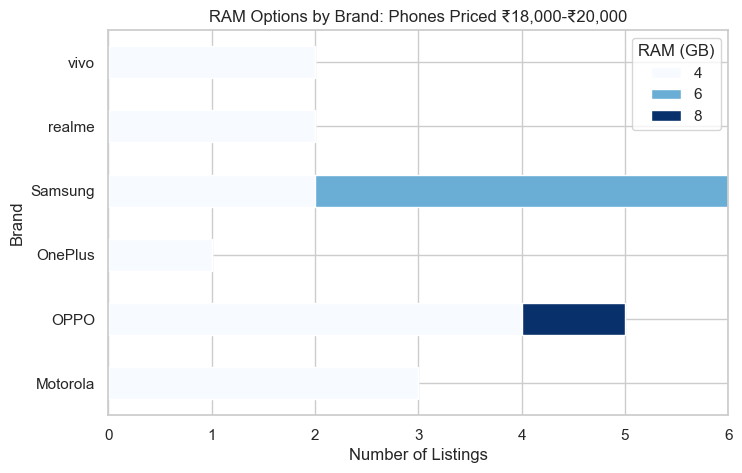

In [28]:
ram_ct = pd.crosstab(df_18_20["brand"], df_18_20["ram_gb"])
ram_ct.plot(kind="barh", stacked=True, figsize=(8, 5), colormap="Blues")
plt.title("RAM Options by Brand: Phones Priced ₹18,000-₹20,000")
plt.xlabel("Number of Listings")
plt.ylabel("Brand")
plt.legend(title="RAM (GB)")
plt.savefig("images/05_ram_by_brand_18k_20k.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Q3: Which Phone Is the Best and Most Affordable Buy?

In [29]:
df_20k[["rating", "rating_count", "bought_past_month"]].describe()

,rating,rating_count,bought_past_month
count,48.000000,48.000000,36.000000
mean,3.758333,330.270833,1625.000000
std,0.380835,367.551052,1662.377815
min,3.000000,6.000000,50.000000
25%,3.575000,55.500000,275.000000
50%,3.800000,157.000000,1000.000000
75%,4.100000,539.000000,3000.000000
max,4.500000,1300.000000,5000.000000


In [30]:
q3 = df_20k.dropna(subset=["rating", "rating_count", "bought_past_month"]).copy()
q3 = q3[q3["rating_count"] >= 100]
q3 = q3.drop_duplicates(subset=["brand", "ram_gb", "rating", "rating_count"])
q3.shape

(15, 10)

In [31]:
cols = ["brand", "product_name", "ram_gb", "selling_price", "rating", "rating_count", "bought_past_month"]
q3.sort_values(["rating", "bought_past_month"], ascending=False)[cols].head(10)

,brand,product_name,ram_gb,selling_price,rating,rating_count,bought_past_month
0,Samsung,"Samsung Galaxy M17e 5G Mobile (Blitz Blue, 6GB RAM, 128GB Storage,...",6,19499.0,4.1,1300.0,2000.0
130,OPPO,OPPO k14x 5g (Ice Blue) (4gb+128gb),4,18897.0,4.1,254.0,1000.0
129,OPPO,"OPPO K14x (Prism Violet, 4GB RAM, 128GB Storage) | 50MP Camera | 6...",4,18915.0,4.1,143.0,500.0
24,vivo,"vivo Y11 5G (Cosmic Gold, 4GB RAM, 64GB Storage) with No Cost EMI/...",4,18999.0,4.1,154.0,300.0
134,vivo,Vivo T4 Lite 5G Titanium Gold_128GB+4GB,4,19999.0,4.1,581.0,100.0
6,Redmi,Redmi 15C 5G Prime Edition Dusk Purple 6GB + 128GB | Massive 6000m...,6,17999.0,4.0,710.0,5000.0
12,Samsung,"Samsung Galaxy F70e 5G (Spotlight Blue, 128 GB) (6 GB RAM) | 6000 ...",6,18888.0,3.9,105.0,2000.0
61,Samsung,"Samsung Galaxy F70e 5G (Limelight Green, 128 GB) (6 GB RAM) | 6000...",6,18450.0,3.9,151.0,1000.0
25,Samsung,"Samsung Galaxy M17e 5G Mobile (Vibe Violet, 4GB RAM, 128GB Storage...",4,16498.0,3.8,1200.0,5000.0
168,Lava,"Lava Bold N2 5G (Regal Gold, 4GB RAM, 128GB Storage) | 6000 mAh Su...",4,14498.0,3.8,276.0,500.0


In [32]:
q3["price_rank"] = q3["selling_price"].rank(ascending=True)
q3["rating_rank"] = q3["rating"].rank(ascending=False)
q3["buyers_rank"] = q3["bought_past_month"].rank(ascending=False)
q3["avg_rank"] = ((q3["price_rank"] + q3["rating_rank"] + q3["buyers_rank"]) / 3).round(1)
q3.sort_values("avg_rank")[cols + ["avg_rank"]].head(10)

,brand,product_name,ram_gb,selling_price,rating,rating_count,bought_past_month,avg_rank
6,Redmi,Redmi 15C 5G Prime Edition Dusk Purple 6GB + 128GB | Massive 6000m...,6,17999.0,4.0,710.0,5000.0,4.7
25,Samsung,"Samsung Galaxy M17e 5G Mobile (Vibe Violet, 4GB RAM, 128GB Storage...",4,16498.0,3.8,1200.0,5000.0,5.5
57,Lava,"Lava Bold N2 (Indus Black, 4 GB RAM, 64 GB Storage) | 13MP AI Dual...",4,8899.0,3.7,807.0,4000.0,5.8
58,Redmi,"Redmi 15C 5G Prime Edition (Dusk Purple, 4GB + 128GB) | Massive 60...",4,15999.0,3.2,539.0,5000.0,7.0
130,OPPO,OPPO k14x 5g (Ice Blue) (4gb+128gb),4,18897.0,4.1,254.0,1000.0,7.7
0,Samsung,"Samsung Galaxy M17e 5G Mobile (Blitz Blue, 6GB RAM, 128GB Storage,...",6,19499.0,4.1,1300.0,2000.0,7.7
12,Samsung,"Samsung Galaxy F70e 5G (Spotlight Blue, 128 GB) (6 GB RAM) | 6000 ...",6,18888.0,3.9,105.0,2000.0,7.8
86,Lava,"Lava Bold N2 Lite (Nilgiri Blue, 3 GB RAM, 64 GB Storage) | 6.75"" ...",3,8099.0,3.7,283.0,500.0,8.2
168,Lava,"Lava Bold N2 5G (Regal Gold, 4GB RAM, 128GB Storage) | 6000 mAh Su...",4,14498.0,3.8,276.0,500.0,8.2
61,Samsung,"Samsung Galaxy F70e 5G (Limelight Green, 128 GB) (6 GB RAM) | 6000...",6,18450.0,3.9,151.0,1000.0,8.2


Chart: price vs rating vs purchases

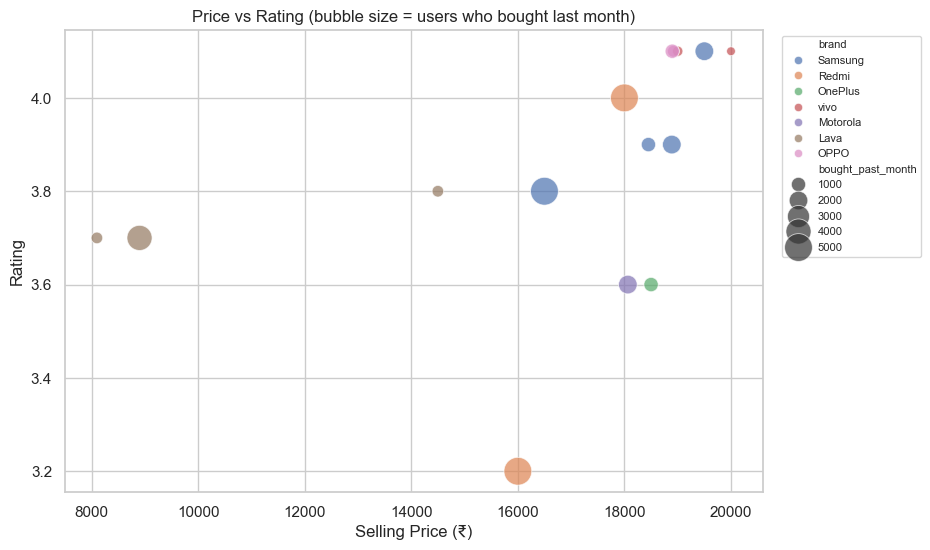

In [33]:
plt.figure(figsize=(9, 6))
sns.scatterplot(data=q3, x="selling_price", y="rating", hue="brand",
                size="bought_past_month", sizes=(40, 400), alpha=0.7)
plt.title("Price vs Rating (bubble size = users who bought last month)")
plt.xlabel("Selling Price (₹)")
plt.ylabel("Rating")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.savefig("images/03_price_rating_purchases.png", dpi=150, bbox_inches="tight")
plt.show()

### Q3 Finding
- **Best all-round buy: Redmi 15C 5G Prime Edition (6 GB + 128 GB) at ₹17,999.** It has the best combined rank across price, rating (4.0, from 710 ratings) and buyers (5K+ bought last month).
- **Highest rating with the most reviews: Samsung Galaxy M17e 6 GB (₹19,499).** It has a 4.1 rating from 1,300 ratings and 2K+ buyers last month.
- **Cheapest well-reviewed option: Lava Bold N2 (4 GB / 64 GB) at ₹8,899**, with a 3.7 rating from 807 ratings and 4K+ buyers, though it has the weakest specifications.
- **Rating and sales do not always agree:** the 4 GB version of the Redmi 15C has 5K+ buyers but only a 3.2 rating.
- **Method:** only phones priced at or below ₹20,000 with at least 100 ratings and a purchase count were considered (15 models). Colour variants were merged. Price, rating and buyers were ranked and averaged with equal weight.
- **Limitations:** "bought last month" is Amazon's rounded lower bound (for example 5K+), so many phones tie at the top. 12 of the 48 phones under ₹20,000 had no purchase count and were left out. The gaps between the top three average ranks are small.

## 5. Q4: Which Brand Gives the Maximum Discount During the Festival Sale?

In [34]:
df["discount_rs"] = df["mrp"] - df["selling_price"]
df[["discount_pct", "discount_rs"]].describe()

,discount_pct,discount_rs
count,157.000000,157.000000
mean,27.617834,12226.216306
std,13.808458,8788.678489
min,1.000000,500.000000
25%,17.000000,5000.000000
50%,29.000000,12000.000000
75%,39.000000,17000.000000
max,57.000000,40000.000000


In [35]:
disc = df.dropna(subset=["discount_pct"]).copy()
brand_disc = disc.groupby("brand").agg(phones=("discount_pct", "count"),
                                       avg_discount_pct=("discount_pct", "mean"),
                                       max_discount_pct=("discount_pct", "max"),
                                       avg_discount_rs=("discount_rs", "mean")).round(1)
brand_disc[brand_disc["phones"] >= 5].sort_values("avg_discount_pct", ascending=False)

,phones,avg_discount_pct,max_discount_pct,avg_discount_rs
brand,,,,
OPPO,24,35.5,49.0,15075.6
Redmi,11,34.2,47.0,12909.2
vivo,11,30.7,54.0,12477.2
Motorola,13,29.1,45.0,10732.7
realme,15,29.1,48.0,12095.2
Lava,8,27.8,32.0,4375.2
Samsung,32,24.9,43.0,14423.3
Poco,6,23.3,57.0,9426.7
Nothing,9,22.3,43.0,12264.1


In [36]:
festival = disc[disc["sale_badge"].isin(["Great Indian Festival", "Mega Festival Deal"])]
festival.groupby("brand")["discount_pct"].agg(["count", "mean", "max"]).round(1).sort_values("mean", ascending=False)

,count,mean,max
brand,,,
Redmi,8,35.0,47.0
iQOO,2,29.0,29.0
Xiaomi,1,24.0,24.0
Samsung,8,20.4,34.0
OnePlus,16,18.2,36.0
realme,1,13.0,13.0


Chart: average discount by brand

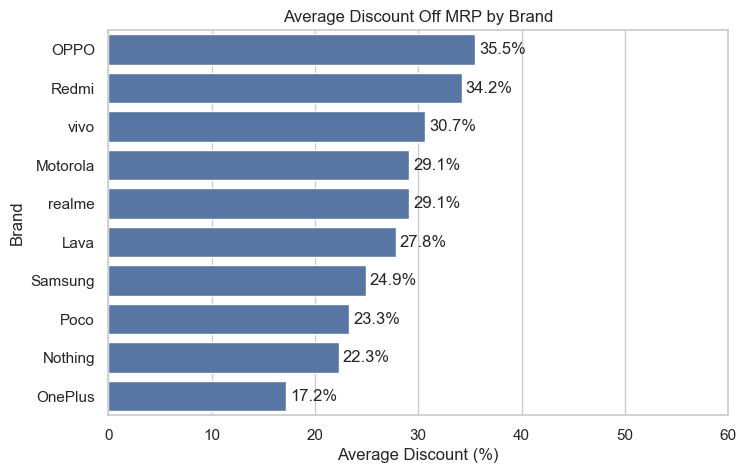

In [37]:
plot_d = brand_disc[brand_disc["phones"] >= 5].sort_values("avg_discount_pct", ascending=False).reset_index()

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=plot_d, x="avg_discount_pct", y="brand", color="#4C72B0")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.xlim(0, 60)
plt.title("Average Discount Off MRP by Brand")
plt.xlabel("Average Discount (%)")
plt.ylabel("Brand")
plt.savefig("images/04_avg_discount_by_brand.png", dpi=150, bbox_inches="tight")
plt.show()

### Q4 Finding
- **Overall, OPPO gives the highest average discount:** 35.5% off MRP across 24 phones (about ₹15,076 off per phone), followed by Redmi (34.2%) and vivo (30.7%). OnePlus gives the lowest (17.2%).
- **Among phones carrying a festival-sale tag (Great Indian Festival or Mega Festival Deal), Redmi leads** with an average of 35.0% across 8 phones. Samsung (20.4%, 8 phones) and OnePlus (18.2%, 16 phones) follow. No OPPO, vivo or Motorola phone carried a festival tag in this data.
- **The biggest single discount is 57%** (Poco M8 5G, priced ₹23,904 against an MRP of ₹54,999).
- **Rupee vs percentage:** Samsung's average discount of ₹14,423 is large because it includes expensive models, even though its percentage (24.9%) is below OPPO, Redmi and vivo.
- **Important context:** discounts are measured against MRP, and many MRPs sit far above the usual selling price, so a high discount percentage does not necessarily mean a cheap or better deal. The data does not mention Dussehra by name, so this reflects Amazon's festival-sale listings in October 2026 and not a Dussehra-only sale. This analysis covers all scraped phones, not only those under ₹20,000.
- **Limitations:** 43 listings had no discount value. Brands with fewer than 5 phones were excluded from the comparison.

## SUMMARY AND CONCLUSION

## 6. Key Findings
1. **Most affordable brand: Lava** (median ₹11,698, cheapest phone ₹8,099). OPPO (9 variants) and Samsung (8) offer the most choice under ₹20,000.
2. **Best RAM at ₹18,000-₹20,000: OPPO K13 5G with 8 GB** (₹19,980). Samsung is the most consistent at 6 GB. 74% of phones in this range have only 4 GB.
3. **Best and affordable buy: Redmi 15C Prime (6 GB + 128 GB) at ₹17,999**, based on the combined rank of price, rating and buyers. Samsung Galaxy M17e 6 GB has the highest rating with the most reviews.
4. **Maximum discount: OPPO overall (35.5% average); Redmi among festival-tagged phones (35.0%).**

## 7. Limitations
- The data is a one-time snapshot of Amazon.in search results from October 2026, not the full market.
- Only 48 phones are priced at or below ₹20,000, and 25 listings had no price.
- Sponsored placements and repeated listings (colour variants) can bias counts, so duplicates were removed and variants merged.
- "Bought last month" is a rounded minimum, and discounts are measured against MRP, which can be inflated.
- The data does not name Dussehra, so discounts reflect Amazon's festival-sale listings.

## 8. Recommendations
- For the lowest price, Lava; for the most RAM, OPPO; for the best overall balance, Redmi 15C Prime (6 GB).
- Compare the actual selling price, not the discount percentage, when judging a deal.
- A follow-up analysis could track the same listings over several weeks to see how prices move before and after the sale.